## 1. Setup and Configuration

In [1]:
import os
import re
import io
import json
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from xml.etree import ElementTree as ET
from scipy import ndimage
from IPython.display import display

BASE_URL = "https://oderest.rsl.wustl.edu/live2/"
PRODUCT_ID = "hrs00002847_07_if173j_mtr3"
DATA_DIR = Path("crism_data")
DATA_DIR.mkdir(exist_ok=True)

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "TerraMatchAI-Research/1.0"})

np.set_printoptions(suppress=True, precision=6)

## 2. ODE Catalog Search
Retrieve CRISM product information from the ODE REST API. Filter the returned catalog records to MRO / CRISM because the IIPT response may include records from other instruments or missions.

In [3]:
def ode_get(params, timeout=90):
    response = SESSION.get(BASE_URL, params=params, timeout=timeout)
    response.raise_for_status()
    return response.json()

iipt_data = ode_get({
    "query": "iipt",
    "target": "mars",
    "ihid": "MRO",
    "output": "JSON"
})

iipt_sets = iipt_data["ODEResults"]["IIPTSets"]["IIPTSet"]
if isinstance(iipt_sets, dict):
    iipt_sets = [iipt_sets]

crism_sets = [
    item for item in iipt_sets
    if str(item.get("ODEMetaDB", "")).lower() == "mars"
    and str(item.get("IHID", "")).upper() == "MRO"
    and str(item.get("IID", "")).upper() == "CRISM"
]

print(f"CRISM catalog entries: {len(crism_sets)}")
display(pd.DataFrame([
    {
        "Product_Type": item.get("PT"),
        "Number_Products": item.get("NumberProducts"),
    }
    for item in crism_sets
]))

CRISM catalog entries: 48


,Product_Type,Number_Products
0,ANCILL,7458
1,CDR,3177211
2,DDR,1022029
3,DDR,1022029
4,DDR,1022029
5,DDR,1022029
6,DDR,1022029
7,DDR,1022029
8,DDR,1022029
9,DDR,1022029


## 3. Select the MTRDR Observation
Search the MRO CRISM MTRDR catalog and select the previously inspected observation by its exact PDS product ID. The selection is explicit so it does not depend on API result ordering.

In [5]:
product_data = ode_get({
    "query": "product",
    "results": "fp",
    "output": "JSON",
    "limit": 100,
    "target": "mars",
    "ihid": "MRO",
    "iid": "CRISM",
    "pt": "MTRDR"
})

products = product_data["ODEResults"]["Products"]["Product"]
if isinstance(products, dict):
    products = [products]

product = next(
    (item for item in products
     if str(item.get("pdsid", "")).lower() == PRODUCT_ID.lower()),
    None
)

if product is None:
    available_ids = [item.get("pdsid") for item in products]
    raise ValueError(
        f"{PRODUCT_ID} was not returned. Returned IDs: {available_ids}. "
        "Increase the catalog limit or search the product ID in ODE."
    )

product_summary = {
    "Product_ID": product.get("pdsid"),
    "Dataset_ID": product.get("Data_Set_Id"),
    "Instrument_Host": product.get("ihid"),
    "Instrument": product.get("iid"),
    "Volume_ID": product.get("PDSVolume_Id"),
    "Label_File": product.get("LabelFileName"),
    "Creation_Time": product.get("Product_creation_time")
}
display(pd.DataFrame([product_summary]))

,Product_ID,Dataset_ID,Instrument_Host,Instrument,Volume_ID,Label_File,Creation_Time
0,hrs00002847_07_if173j_mtr3,mro_crism_mtrdr,MRO,CRISM,MROCR_4001,hrs00002847_07_if173j_mtr3.xml,2017-07-18T13:43:57Z


## 4. Inspect Product Files
Summarize the file inventory and identify the IF cube, SU parameter maps, and wavelength table. Browse files are excluded from the printed list to keep the notebook concise.

In [6]:
product_files = product.get("Product_files", {}).get("Product_file", [])
if isinstance(product_files, dict):
    product_files = [product_files]

def get_file_name(file_record):
    return str(file_record.get("FileName", file_record.get("filename", "")))

def get_file_url(file_record):
    raw = str(file_record.get("URL", file_record.get("url", ""))).strip()
    match = re.search(r"\((https?://[^)]+)\)", raw)
    if match:
        return match.group(1)
    match = re.search(r"https?://\S+", raw)
    return match.group(0).rstrip(")") if match else raw

file_types = Counter(str(f.get("Type", "Unknown")) for f in product_files)
print("File categories:", dict(file_types))

selected_files = [
    f for f in product_files
    if any(token in get_file_name(f).upper()
           for token in ["_IF173J_MTR3", "_SU173J_MTR3", "_WV173J_MTR3"])
    and not get_file_name(f).upper().endswith((".PNG", ".JPG", ".JPEG"))
]
display(pd.DataFrame([
    {
        "File_Name": get_file_name(f),
        "Type": f.get("Type"),
        "Size_KB": f.get("FileSize"),
        "URL": get_file_url(f)
    }
    for f in selected_files
]))

File categories: {'Browse': 92, 'Product': 23, 'Derived': 3, 'Referenced': 1}


,File_Name,Type,Size_KB,URL
0,HRS00002847_07_IF173J_MTR3.HDR,Product,None,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
1,HRS00002847_07_IF173J_MTR3.IMG,Product,None,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
2,HRS00002847_07_IF173J_MTR3.LBL,Product,None,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
3,HRS00002847_07_IF173J_MTR3.XML,Product,None,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
4,HRS00002847_07_IF173J_MTR3_XML.KML,Derived,None,https://ode.rsl.wustl.edu/mars/datafile/kmlfil...
5,HRS00002847_07_IF173J_MTR3_XML.TAR.GZ,Derived,None,https://ode.rsl.wustl.edu/mars/datafile/shapef...
6,HRS00002847_07_IF173J_MTR3_XML.ZIP,Derived,None,https://ode.rsl.wustl.edu/mars/datafile/shapef...
7,HRS00002847_07_SU173J_MTR3.HDR,Product,None,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
8,HRS00002847_07_SU173J_MTR3.IMG,Product,None,https://pds-geosciences.wustl.edu/mro/mro-m-cr...
9,HRS00002847_07_SU173J_MTR3.LBL,Product,None,https://pds-geosciences.wustl.edu/mro/mro-m-cr...


## 5. Download Required Files
Download only the IF cube, its label/header, the SU parameter product, and the WV wavelength table.

In [7]:
def find_product_file(token, extension):
    matches = [
        f for f in product_files
        if token.upper() in get_file_name(f).upper()
        and get_file_name(f).upper().endswith(extension.upper())
    ]
    if not matches:
        raise FileNotFoundError(f"Could not find {token} {extension} in the product file list.")
    return matches[0]

def download_file(file_record, force=False):
    url = get_file_url(file_record)
    filename = get_file_name(file_record)
    if not url.startswith("http"):
        raise ValueError(f"Invalid file URL for {filename}: {url}")

    destination = DATA_DIR / filename
    if destination.exists() and not force:
        return destination

    response = SESSION.get(url, timeout=180)
    response.raise_for_status()
    destination.write_bytes(response.content)
    print(f"Downloaded {filename}: {destination.stat().st_size:,} bytes")
    return destination

if_xml_path = download_file(find_product_file("IF173J_MTR3", ".XML"))
if_hdr_path = download_file(find_product_file("IF173J_MTR3", ".HDR"))
if_img_path = download_file(find_product_file("IF173J_MTR3", ".IMG"))

su_xml_path = download_file(find_product_file("SU173J_MTR3", ".XML"))
su_hdr_path = download_file(find_product_file("SU173J_MTR3", ".HDR"))
su_img_path = download_file(find_product_file("SU173J_MTR3", ".IMG"))

wv_tab_path = download_file(find_product_file("WV173J_MTR3", ".TAB"))

print("All required files are available.")

Downloaded HRS00002847_07_IF173J_MTR3.XML: 14,994 bytes
Downloaded HRS00002847_07_IF173J_MTR3.HDR: 14,848 bytes
Downloaded HRS00002847_07_IF173J_MTR3.IMG: 126,889,632 bytes
Downloaded HRS00002847_07_SU173J_MTR3.XML: 66,661 bytes
Downloaded HRS00002847_07_SU173J_MTR3.HDR: 1,808 bytes
Downloaded HRS00002847_07_SU173J_MTR3.IMG: 15,569,280 bytes
Downloaded HRS00002847_07_WV173J_MTR3.TAB: 14,670 bytes
All required files are available.


## 6. Read Product Metadata
Read the PDS4 labels and ENVI header. The XML label is used as the authoritative source for the product type and array metadata.

In [8]:
def parse_xml(path):
    return ET.parse(path).getroot()

if_root = parse_xml(if_xml_path)
su_root = parse_xml(su_xml_path)

def local_name(tag):
    return tag.split("}")[-1]

def first_text(root, tag_name):
    for element in root.iter():
        if local_name(element.tag) == tag_name and element.text:
            return element.text.strip()
    return None

metadata_tags = [
    "logical_identifier", "title", "start_date_time",
    "stop_date_time", "solar_longitude", "product_type",
    "orbit_number", "observation_type", "observation_id"
]
metadata = {tag: first_text(if_root, tag) for tag in metadata_tags}
display(pd.DataFrame([metadata]))

def read_envi_header(path):
    text = Path(path).read_text(errors="ignore")
    header = {}
    for line in text.splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            header[key.strip().lower()] = value.strip()
    return header

if_hdr = read_envi_header(if_hdr_path)
su_hdr = read_envi_header(su_hdr_path)

for key in ["samples", "lines", "bands", "data type", "interleave", "byte order", "data ignore value"]:
    print(f"{key}: {if_hdr.get(key)}")

,logical_identifier,title,start_date_time,stop_date_time,solar_longitude,product_type,orbit_number,observation_type,observation_id
0,urn:nasa:pds:mro_crism_mtrdr:data_mtrdr:hrs000...,hrs00002847_07_if173j_mtr3 MTRDR IF,2006-09-30T22:59:53.837Z,2006-09-30T23:00:49.571Z,114.160829,MTRDR,840,HRS,16#00002847#


samples: 318
lines: 204
bands: 489
data type: 4
interleave: bsq
byte order: 0
data ignore value: 6.55350000e+04


## 7. Load the Hyperspectral IF Cube
The IF cube is stored as 32-bit little-endian floating-point data in BSQ order. The raw array shape is `(bands, lines, samples)`.

In [9]:
samples = int(if_hdr["samples"])
lines = int(if_hdr["lines"])
bands = int(if_hdr["bands"])
dtype_code = int(if_hdr["data type"])
interleave = if_hdr.get("interleave", "").lower()
byte_order = int(if_hdr.get("byte order", "0"))
ignore_value = float(if_hdr.get("data ignore value", "65535"))

if dtype_code != 4 or interleave != "bsq":
    raise ValueError(f"Unexpected IF format: data type={dtype_code}, interleave={interleave}")

cube_dtype = "<f4" if byte_order == 0 else ">f4"
expected_bytes = samples * lines * bands * 4
actual_bytes = if_img_path.stat().st_size
print(f"Expected bytes: {expected_bytes:,}")
print(f"Actual bytes:   {actual_bytes:,}")
if expected_bytes != actual_bytes:
    raise ValueError("IMG file size does not match the dimensions in the header.")

cube = np.memmap(
    if_img_path, dtype=cube_dtype, mode="r",
    shape=(bands, lines, samples)
)

print("Cube shape:", cube.shape)
print("Cube dtype:", cube.dtype)

Expected bytes: 126,889,632
Actual bytes:   126,889,632
Cube shape: (489, 204, 318)
Cube dtype: float32


## 8. Read Wavelengths and Validate Spectral Alignment
The WV table maps each cube band to its wavelength. `rownum` is a detector row identifier, not the cube band index.

In [10]:
wv_columns = ["spect_id", "rownum", "wavelength", "fwhm", "bad_band_id"]
wv_df = pd.read_csv(
    wv_tab_path, header=None, names=wv_columns, skipinitialspace=True
)

if len(wv_df) != bands:
    raise ValueError(f"WV records ({len(wv_df)}) do not match cube bands ({bands}).")

wavelengths = wv_df["wavelength"].to_numpy(dtype=float)
good_band_mask = wv_df["bad_band_id"].to_numpy() == 1

print("WV records:", len(wavelengths))
print("Wavelengths increasing:", bool(np.all(np.diff(wavelengths) > 0)))
print(f"Wavelength range: {wavelengths.min():.2f}–{wavelengths.max():.2f} nm")
print("Bad-band flags:", wv_df["bad_band_id"].value_counts().to_dict())

WV records: 489
Wavelengths increasing: True
Wavelength range: 436.13–3896.76 nm
Bad-band flags: {1: 489}


## 9. Data Quality Assessment
Mask the product's NoData value before calculating statistics. The invalid percentage below refers to spectral samples, not the percentage of spatial pixels.

In [11]:
cube_sample = np.asarray(cube, dtype=np.float32)
valid_cube = np.isfinite(cube_sample) & (cube_sample != ignore_value)

total_samples = cube_sample.size
valid_samples = int(valid_cube.sum())
invalid_samples = total_samples - valid_samples

print(f"Total spectral samples: {total_samples:,}")
print(f"Valid spectral samples: {valid_samples:,}")
print(f"Invalid spectral samples: {invalid_samples:,}")
print(f"Invalid sample percentage: {100 * invalid_samples / total_samples:.2f}%")

valid_values = cube_sample[valid_cube]
print("Valid value statistics:")
print(pd.Series(valid_values).describe(percentiles=[0.25, 0.5, 0.75]))

Total spectral samples: 31,722,408
Valid spectral samples: 22,181,090
Invalid spectral samples: 9,541,318
Invalid sample percentage: 30.08%
Valid value statistics:
count    2.218109e+07
mean     3.115707e-01
std      1.303973e-01
min      6.252809e-03
25%      2.174117e-01
50%      3.562734e-01
75%      4.056052e-01
max      6.472155e-01
dtype: float64


## 10. False-Color Preview
Use the default ENVI display bands (1-based band numbers 304, 122, and 41). This is a visualization composite, not a natural-color image.

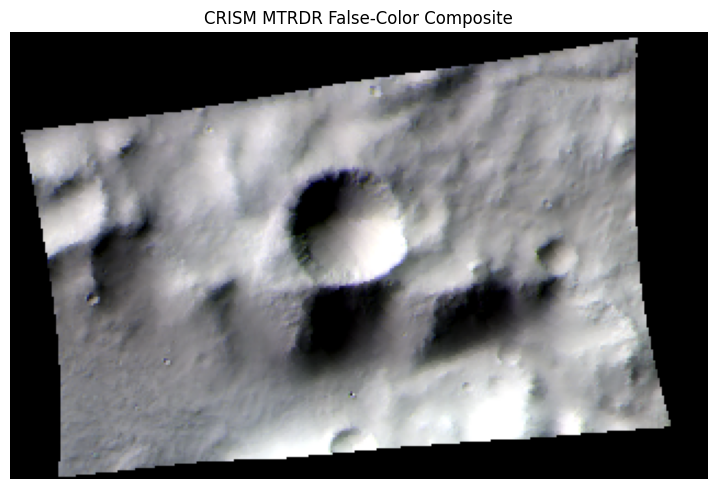

In [12]:
rgb_band_numbers = [304, 122, 41]
rgb_indices = [band_number - 1 for band_number in rgb_band_numbers]

rgb = np.stack([cube_sample[index] for index in rgb_indices], axis=-1)
rgb_valid = np.all(np.isfinite(rgb) & (rgb != ignore_value), axis=-1)

def percentile_stretch(channel, mask, low=2, high=98):
    values = channel[mask]
    lo, hi = np.percentile(values, [low, high])
    stretched = (channel - lo) / (hi - lo) if hi > lo else np.zeros_like(channel)
    return np.clip(stretched, 0, 1)

rgb_display = np.zeros_like(rgb, dtype=np.float32)
for channel_index in range(3):
    rgb_display[..., channel_index] = percentile_stretch(
        rgb[..., channel_index], rgb_valid
    )

rgb_display[~rgb_valid] = 0

plt.figure(figsize=(9, 6))
plt.imshow(rgb_display)
plt.title("CRISM MTRDR False-Color Composite")
plt.axis("off")
plt.show()

## 11. Spectral Signature Analysis
Inspect one valid pixel and preserve wavelength gaps. Do not connect samples across large gaps in the wavelength table.

Selected pixel: row=100, column=150
Valid bands: 487 / 489


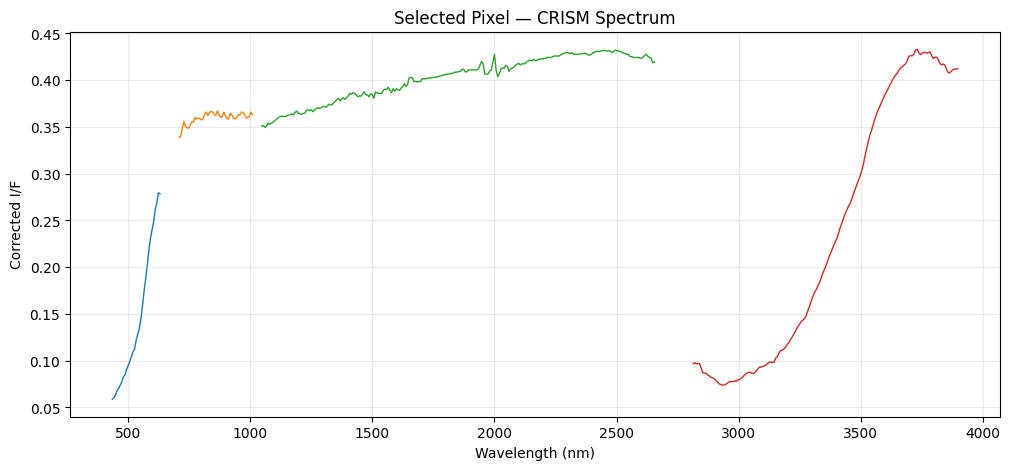

In [13]:
row, col = 100, 150
pixel_spectrum = cube_sample[:, row, col].astype(float)
pixel_valid = np.isfinite(pixel_spectrum) & (pixel_spectrum != ignore_value) & good_band_mask

print(f"Selected pixel: row={row}, column={col}")
print(f"Valid bands: {pixel_valid.sum()} / {bands}")

# Split the spectrum where wavelength gaps exceed 30 nm.
gap_breaks = np.where(np.diff(wavelengths) > 30)[0] + 1
segments = np.split(np.arange(bands), gap_breaks)

plt.figure(figsize=(12, 5))
for segment in segments:
    idx = segment[pixel_valid[segment]]
    if len(idx):
        plt.plot(wavelengths[idx], pixel_spectrum[idx], linewidth=1)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Corrected I/F")
plt.title("Selected Pixel — CRISM Spectrum")
plt.grid(alpha=0.25)
plt.show()

## 12. Focused Spectral Region
The 2.15–2.65 µm region is inspected separately. Avoid interpreting simple local minima as confirmed mineral detections without checking index definitions and product quality information.

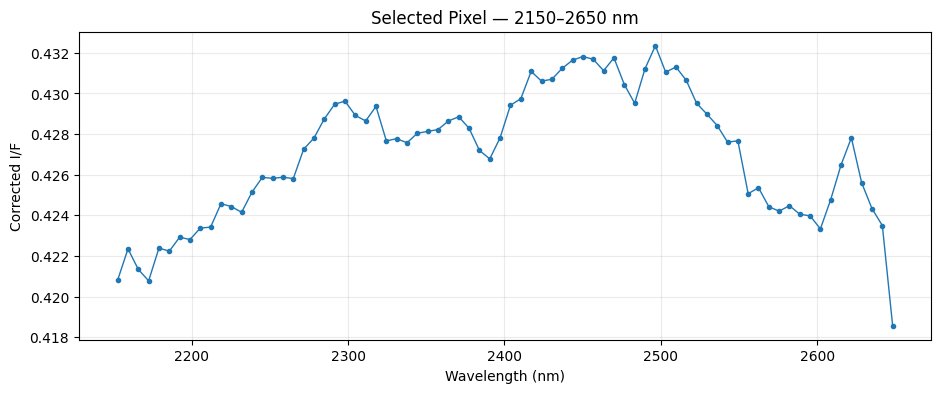

,Wavelength_nm,Corrected_IF
0,2152.51,0.420817
1,2159.12,0.422351
2,2165.72,0.421344
3,2172.33,0.420779
4,2178.94,0.422393
5,2185.55,0.422238
6,2192.16,0.422926
7,2198.77,0.422810
8,2205.38,0.423374
9,2211.99,0.423424


In [14]:
region_mask = (
    pixel_valid
    & (wavelengths >= 2150)
    & (wavelengths <= 2650)
)

plt.figure(figsize=(11, 4))
plt.plot(wavelengths[region_mask], pixel_spectrum[region_mask], marker=".", linewidth=1)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Corrected I/F")
plt.title("Selected Pixel — 2150–2650 nm")
plt.grid(alpha=0.25)
plt.show()

region_table = pd.DataFrame({
    "Wavelength_nm": wavelengths[region_mask],
    "Corrected_IF": pixel_spectrum[region_mask]
})
display(region_table.head(10))

## 13. Known Spectral Cautions
The CRISM dataset documentation reports known issues in parts of the spectrum, including approximately 2660–2800 nm and a suspect spectral shape over approximately 3100–3800 nm. These regions should not be used for unqualified mineral interpretation.

The WV table's good-channel flag does not guarantee that all systematic calibration artifacts are absent. The `IN` product and the full product documentation should be consulted for detailed processing-quality assessment.

## 14. Read SU Spectral Summary Parameter Maps
The SU product contains multiple 2D parameter maps stored sequentially in one IMG file. Array offsets are extracted from the SU XML label rather than hard-coded.

In [15]:
def get_array_metadata(root):
    records = []
    for array_element in root.iter():
        if local_name(array_element.tag) != "Array_2D_Image":
            continue

        record = {}
        for child in array_element.iter():
            tag = local_name(child.tag)
            if tag in {"name", "local_identifier", "offset", "axes", "data_type"}:
                if child.text and tag not in record:
                    record[tag] = child.text.strip()

            if tag == "Element_Array":
                for sub in child.iter():
                    if local_name(sub.tag) == "elements" and sub.text:
                        record.setdefault("dimensions", []).append(int(sub.text.strip()))

        records.append(record)
    return records

su_arrays = get_array_metadata(su_root)
su_array_df = pd.DataFrame(su_arrays)
display(su_array_df.head())

def find_su_offset(parameter_name):
    target = parameter_name.upper()
    for record in su_arrays:
        name = str(record.get("name", "")).upper()
        local_id = str(record.get("local_identifier", "")).upper()
        if name == target or local_id == f"{target}_IMAGE":
            return int(record["offset"])
    raise KeyError(f"{parameter_name} was not found in the SU XML label.")

su_samples = int(su_hdr["samples"])
su_lines = int(su_hdr["lines"])
su_dtype_code = int(su_hdr["data type"])
su_byte_order = int(su_hdr.get("byte order", "0"))

if su_dtype_code != 4:
    raise ValueError("Unexpected SU data type. Expected 32-bit float.")

su_dtype = "<f4" if su_byte_order == 0 else ">f4"
su_ignore_value = float(su_hdr.get("data ignore value", "65535"))

def read_su_map(parameter_name):
    offset = find_su_offset(parameter_name)
    count = su_lines * su_samples
    with open(su_img_path, "rb") as file:
        file.seek(offset)
        data = np.fromfile(file, dtype=su_dtype, count=count)

    if data.size != count:
        raise ValueError(f"Unexpected data length for {parameter_name}.")

    return data.reshape((su_lines, su_samples)).astype(np.float32)

parameter_names = ["OLINDEX3", "LCPINDEX2", "HCPINDEX2"]
parameter_maps = {name: read_su_map(name) for name in parameter_names}

for name, image in parameter_maps.items():
    valid = np.isfinite(image) & (image != su_ignore_value)
    print(f"{name}: shape={image.shape}, valid={valid.sum():,}, invalid={(~valid).sum():,}")

,name,local_identifier,offset,axes,data_type
0,R770,R770_image,0,2,IEEE754LSBSingle
1,RBR,RBR_image,259488,2,IEEE754LSBSingle
2,BD530_2,BD530_2_image,518976,2,IEEE754LSBSingle
3,SH600_2,SH600_2_image,778464,2,IEEE754LSBSingle
4,SH770,SH770_image,1037952,2,IEEE754LSBSingle


OLINDEX3: shape=(204, 318), valid=45,455, invalid=19,417
LCPINDEX2: shape=(204, 318), valid=45,455, invalid=19,417
HCPINDEX2: shape=(204, 318), valid=45,455, invalid=19,417


## 15. Parameter Map Statistics
These parameters are spectral index responses, not direct mineral abundance measurements. Keep the raw values and mask NoData consistently.

In [16]:
common_valid = np.ones((su_lines, su_samples), dtype=bool)

for image in parameter_maps.values():
    common_valid &= np.isfinite(image) & (image != su_ignore_value)

print("Common valid pixels:", int(common_valid.sum()))

stats_rows = []
for name, image in parameter_maps.items():
    values = image[common_valid]
    stats_rows.append({
        "Parameter": name,
        "Mean": float(np.mean(values)),
        "Std": float(np.std(values)),
        "Min": float(np.min(values)),
        "P25": float(np.percentile(values, 25)),
        "Median": float(np.median(values)),
        "P75": float(np.percentile(values, 75)),
        "Max": float(np.max(values))
    })

stats_df = pd.DataFrame(stats_rows)
display(stats_df)

Common valid pixels: 45455


,Parameter,Mean,Std,Min,P25,Median,P75,Max
0,OLINDEX3,0.020716,0.009691,-0.148967,0.014825,0.020906,0.026860,0.163503
1,LCPINDEX2,-0.017187,0.003548,-0.037663,-0.019309,-0.016740,-0.014618,0.000198
2,HCPINDEX2,-0.015389,0.004015,-0.043204,-0.016786,-0.014569,-0.012960,-0.006147


## 16. Parameter Maps
Display each map with percentile-based limits to reduce the visual effect of extreme values. The original data are not modified.

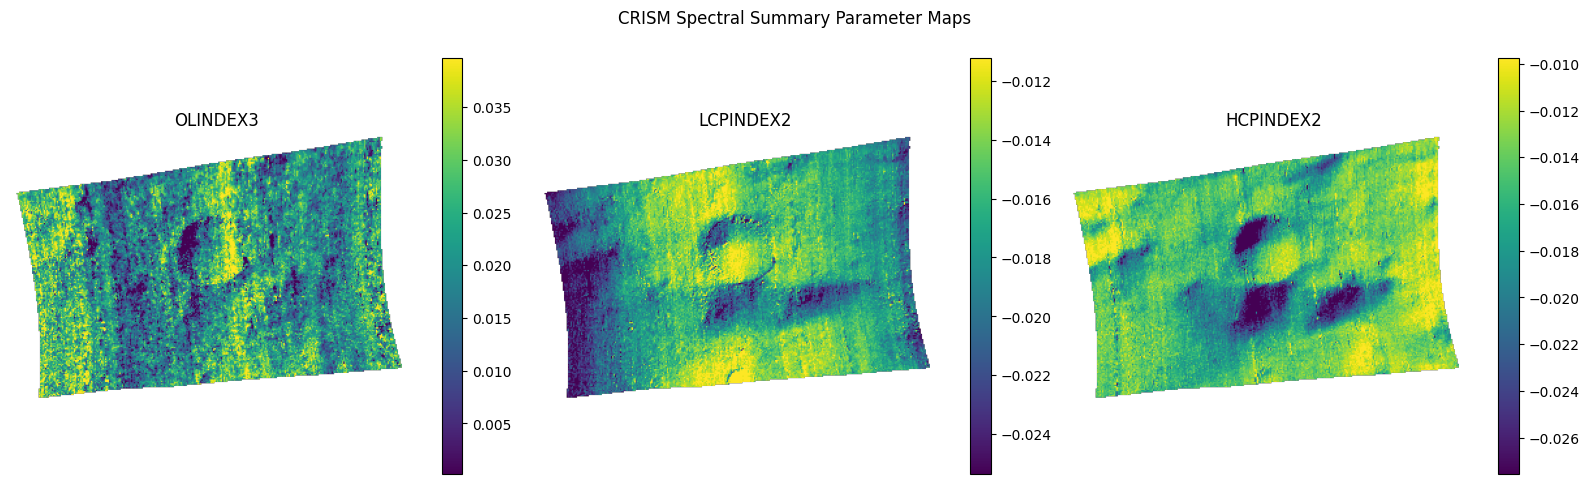

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, name in zip(axes, parameter_names):
    image = parameter_maps[name].astype(float).copy()
    image[~common_valid] = np.nan
    vmin, vmax = np.nanpercentile(image, [2, 98])
    im = ax.imshow(image, cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title(name)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("CRISM Spectral Summary Parameter Maps")
plt.tight_layout()
plt.show()

## 17. Feature Distributions
Plot histograms over the common valid pixels. Extreme values remain in the statistics but the plot uses the 1st–99th percentile range for readability.

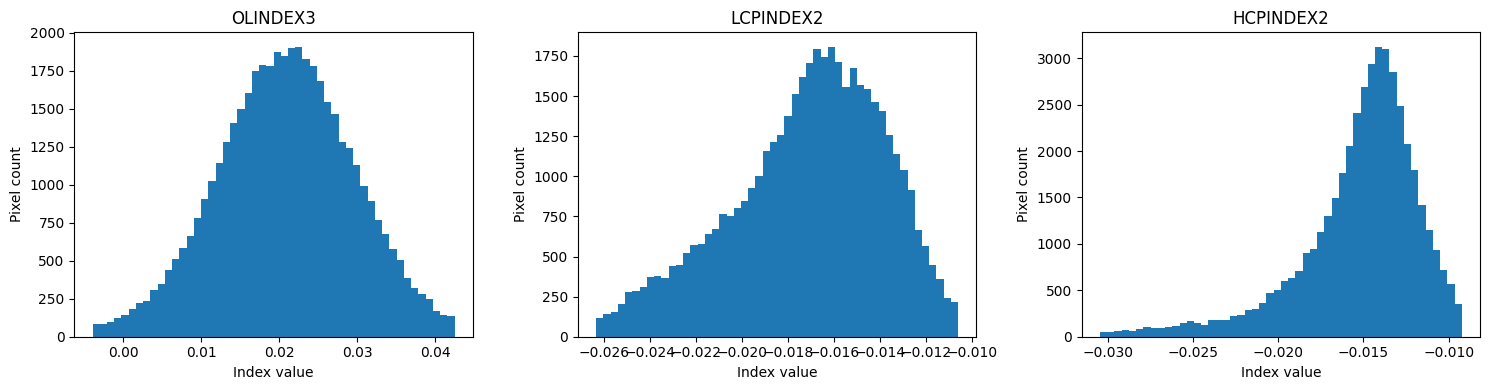

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, parameter_names):
    values = parameter_maps[name][common_valid]
    low, high = np.percentile(values, [1, 99])
    ax.hist(values, bins=50, range=(low, high))
    ax.set_title(name)
    ax.set_xlabel("Index value")
    ax.set_ylabel("Pixel count")

plt.tight_layout()
plt.show()

## 18. Correlation Analysis
Correlations describe linear relationships between the three index maps over common valid pixels. They do not prove mineral co-occurrence or causation.

,OLINDEX3,LCPINDEX2,HCPINDEX2
OLINDEX3,1.0000,-0.1382,0.334
LCPINDEX2,-0.1382,1.0000,0.140
HCPINDEX2,0.3340,0.1400,1.000


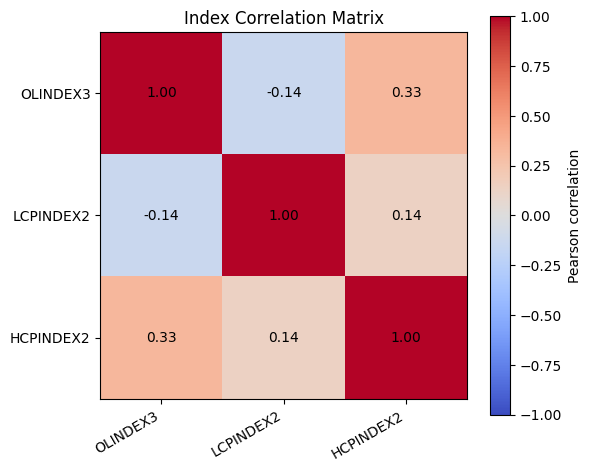

In [19]:
feature_matrix = np.column_stack([
    parameter_maps[name][common_valid] for name in parameter_names
])
feature_df = pd.DataFrame(feature_matrix, columns=parameter_names)
correlation = feature_df.corr()

display(correlation.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(parameter_names)), parameter_names, rotation=30, ha="right")
ax.set_yticks(range(len(parameter_names)), parameter_names)
for i in range(len(parameter_names)):
    for j in range(len(parameter_names)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Index Correlation Matrix")
plt.tight_layout()
plt.show()

## 19. Relative High-Response Regions
Use percentile thresholds to identify relatively high index-response pixels. These are exploratory masks, not mineral detections or abundance maps.

,90,95,99
OLINDEX3,0.032399,0.035668,0.042478
LCPINDEX2,-0.013009,-0.012163,-0.010590
HCPINDEX2,-0.011477,-0.010599,-0.009231


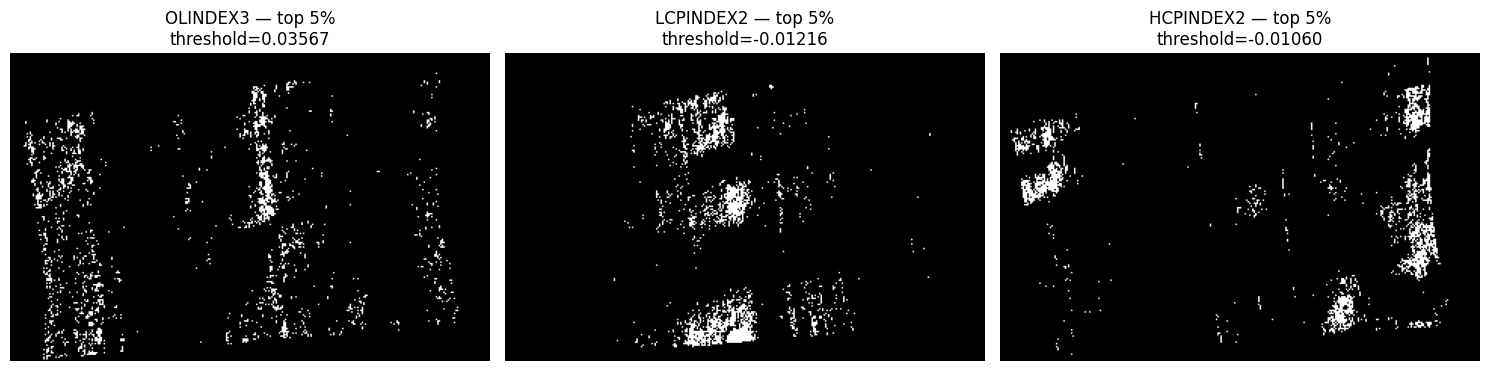

In [20]:
threshold_percentiles = [90, 95, 99]
threshold_results = {}

for name in parameter_names:
    values = parameter_maps[name][common_valid]
    threshold_results[name] = {
        percentile: float(np.percentile(values, percentile))
        for percentile in threshold_percentiles
    }

display(pd.DataFrame(threshold_results).T)

def threshold_mask(name, percentile=95):
    image = parameter_maps[name]
    values = image[common_valid]
    threshold = np.percentile(values, percentile)
    return common_valid & (image >= threshold), float(threshold)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
top_masks = {}

for ax, name in zip(axes, parameter_names):
    mask, threshold = threshold_mask(name, 95)
    top_masks[name] = mask
    ax.imshow(mask, cmap="gray")
    ax.set_title(f"{name} — top 5%\nthreshold={threshold:.5f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 20. Connected Components and Threshold Sensitivity
Connected components group adjacent pixels in a threshold mask. Their sizes depend on the chosen percentile and connectivity rule; they should not automatically be treated as separate geological deposits.

In [21]:
structure_8 = np.ones((3, 3), dtype=int)
sensitivity_rows = []

for name in parameter_names:
    for percentile in [90, 95, 99]:
        mask, threshold = threshold_mask(name, percentile)
        labels, component_count = ndimage.label(mask, structure=structure_8)
        sizes = np.bincount(labels.ravel())[1:]
        largest = int(sizes.max()) if sizes.size else 0

        sensitivity_rows.append({
            "Parameter": name,
            "Top_Percent": 100 - percentile,
            "Threshold": threshold,
            "Selected_Pixels": int(mask.sum()),
            "Connected_Regions": int(component_count),
            "Largest_Region_Pixels": largest
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)

,Parameter,Top_Percent,Threshold,Selected_Pixels,Connected_Regions,Largest_Region_Pixels
0,OLINDEX3,10,0.032399,4546,890,467
1,OLINDEX3,5,0.035668,2273,658,253
2,OLINDEX3,1,0.042478,455,228,36
3,LCPINDEX2,10,-0.013009,4546,490,1143
4,LCPINDEX2,5,-0.012163,2273,369,666
5,LCPINDEX2,1,-0.010590,455,163,109
6,HCPINDEX2,10,-0.011477,4546,505,1173
7,HCPINDEX2,5,-0.010599,2273,305,413
8,HCPINDEX2,1,-0.009231,455,185,48


## 21. High-Response Overlap
Compare the top 5% masks using the same common-valid pixel set. Overlap is a spatial/statistical comparison only; it is not proof that minerals occur together.

,Overlap,Pixels
0,OLINDEX3 & LCPINDEX2,48
1,OLINDEX3 & HCPINDEX2,311
2,LCPINDEX2 & HCPINDEX2,29
3,All three,1


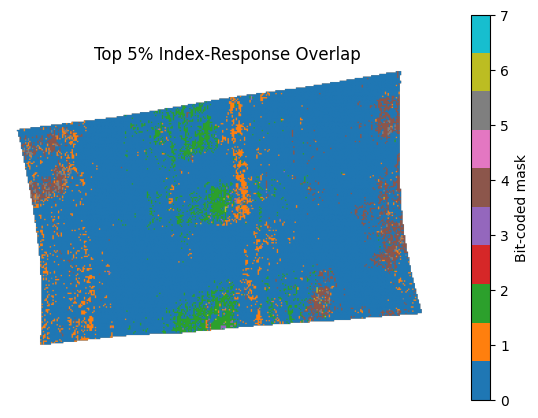

In [22]:
mask_ol = top_masks["OLINDEX3"]
mask_lcp = top_masks["LCPINDEX2"]
mask_hcp = top_masks["HCPINDEX2"]

overlap_counts = {
    "OLINDEX3 & LCPINDEX2": int((mask_ol & mask_lcp).sum()),
    "OLINDEX3 & HCPINDEX2": int((mask_ol & mask_hcp).sum()),
    "LCPINDEX2 & HCPINDEX2": int((mask_lcp & mask_hcp).sum()),
    "All three": int((mask_ol & mask_lcp & mask_hcp).sum())
}

display(pd.DataFrame([
    {"Overlap": key, "Pixels": value}
    for key, value in overlap_counts.items()
]))

fig, ax = plt.subplots(figsize=(7, 5))
overlap_image = (
    mask_ol.astype(int)
    + 2 * mask_lcp.astype(int)
    + 4 * mask_hcp.astype(int)
).astype(float)
overlap_image[~common_valid] = np.nan
im = ax.imshow(overlap_image, cmap="tab10", vmin=0, vmax=7)
ax.set_title("Top 5% Index-Response Overlap")
ax.axis("off")
fig.colorbar(im, ax=ax, label="Bit-coded mask")
plt.show()

## 22. Findings and Limitations
### What this notebook establishes
- The selected CRISM MTRDR observation contains a 489-band hyperspectral IF cube.
- The WV table aligns with the cube's spectral bands.
- The IF cube and SU parameter maps contain NoData samples that must be masked.
- Three spectral summary parameters can be inspected spatially and statistically.
- Percentile masks, connected components, and overlap provide exploratory spatial summaries.

### What it does not establish
- Confirmed mineral identity or mineral abundance.
- A geological interpretation of each connected region.
- A representative analysis of the entire crater or Mars.
- A direct Earth–Mars analog match.

### Next scientific steps
1. Inspect the SU label definitions and CRISM parameter documentation for exact index formulas and interpretation.
2. Review the IN quality maps and processing information.
3. Locate the observation footprint and confirm its geographic context.
4. Repeat the workflow across multiple observations before making regional claims.
5. Only then compare physically compatible features with Earth datasets.